# Partie 2 – Flux Streaming : Mobilité Urbaine (Vélib / CityBikes)

**Source** : CityBikes API — données temps réel stations de vélos en libre-service

### Questions métier
1. Quelles stations présentent le **plus fort taux d'utilisation** ?
2. Peut-on identifier des zones où **l'offre de vélos est insuffisante** ?
3. Quels sont les **pics d'utilisation journaliers** du réseau ?
4. Existe-t-il des **déséquilibres géographiques** dans la disponibilité des vélos ?
5. Peut-on détecter des **stations critiques** nécessitant un rééquilibrage ?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 5)
sns.set_theme(style='whitegrid')
print('Librairies chargées.')

Librairies chargées.


## 1. Génération des données Vélib Paris (snapshots minuterie sur 30 jours)

In [2]:
# Zones Paris avec coordinates réalistes
ZONES = {
    'Centre':    {'lat_c': 48.860, 'lon_c':  2.347, 'n_stations': 120, 'demand_factor': 1.5},
    'Rive Gauche':{'lat_c': 48.845, 'lon_c':  2.330, 'n_stations':  90, 'demand_factor': 1.3},
    'Rive Droite':{'lat_c': 48.875, 'lon_c':  2.355, 'n_stations': 110, 'demand_factor': 1.4},
    'Est Paris':  {'lat_c': 48.860, 'lon_c':  2.400, 'n_stations':  80, 'demand_factor': 1.0},
    'Ouest Paris':{'lat_c': 48.862, 'lon_c':  2.290, 'n_stations':  85, 'demand_factor': 1.1},
    'Nord Paris': {'lat_c': 48.895, 'lon_c':  2.355, 'n_stations':  70, 'demand_factor': 0.9},
    'Sud Paris':  {'lat_c': 48.825, 'lon_c':  2.335, 'n_stations':  65, 'demand_factor': 0.8},
    'Banlieue':   {'lat_c': 48.840, 'lon_c':  2.430, 'n_stations':  50, 'demand_factor': 0.6},
}

# Stations
stations = []
sid = 1
for zone, info in ZONES.items():
    for _ in range(info['n_stations']):
        lat = info['lat_c'] + np.random.normal(0, 0.012)
        lon = info['lon_c'] + np.random.normal(0, 0.018)
        capacity = np.random.choice([15, 20, 25, 30, 35], p=[0.1, 0.3, 0.35, 0.2, 0.05])
        stations.append({
            'station_id': f'VLB{sid:05d}',
            'station_name': f'Station {zone} #{sid}',
            'zone': zone,
            'latitude': lat,
            'longitude': lon,
            'capacity': capacity,
            'demand_factor': info['demand_factor'],
        })
        sid += 1

df_stations = pd.DataFrame(stations)
print(f'{len(df_stations)} stations Vélib générées')

# Snapshots horaires sur 30 jours (pour performance : horaire plutôt que minuterie)
timestamps = pd.date_range('2024-01-01', '2024-01-30 23:00', freq='h')

snap_records = []
t0 = pd.Timestamp.now()
n_st = len(df_stations)
n_ts = len(timestamps)
print(f'Début génération snapshots: stations={n_st}, timestamps={n_ts} (total lignes ≈ {n_st*n_ts:,})')
for i_st, (_, st) in enumerate(df_stations.iterrows(), start=1):
    cap = st['capacity']
    df_factor = st['demand_factor']
    if i_st % 50 == 0 or i_st == 1:
        elapsed = (pd.Timestamp.now() - t0).total_seconds()
        print(f'  station {i_st}/{n_st} ({st["station_id"]}) elapsed={elapsed:.1f}s')
    for ts in timestamps:
        hour = ts.hour
        dow  = ts.dayofweek  # 0=lundi

        # Profil journalier (double pic matin/soir en semaine)
        if dow < 5:  # semaine
            morning  = np.exp(-0.5 * ((hour - 8) / 1.5)**2)
            evening  = np.exp(-0.5 * ((hour - 18) / 1.5)**2)
            utiliz   = df_factor * 0.6 * (0.6 * morning + 0.4 * evening)
        else:  # weekend
            midday   = np.exp(-0.5 * ((hour - 13) / 3.0)**2)
            utiliz   = df_factor * 0.45 * midday

        utiliz = min(0.95, max(0.02, utiliz + np.random.normal(0, 0.05)))
        bikes  = max(0, min(cap, round(cap * (1 - utiliz))))
        free   = max(0, cap - bikes)

        snap_records.append({
            'station_id': st['station_id'],
            'timestamp': ts,
            'bikes_available': bikes,
            'free_slots': free,
            'total_slots': cap,
        })

df_snap = pd.DataFrame(snap_records)
df_snap['utilization_rate'] = (df_snap['bikes_available'] / df_snap['total_slots']).round(3)
df_snap = df_snap.merge(df_stations[['station_id','station_name','zone','latitude','longitude','demand_factor']],
                         on='station_id')
print(f'{len(df_snap):,} snapshots générés')
df_snap.head(3)

670 stations Vélib générées
Début génération snapshots: stations=670, timestamps=720 (total lignes ≈ 482,400)
  station 1/670 (VLB00001) elapsed=0.0s
  station 50/670 (VLB00050) elapsed=1.8s
  station 100/670 (VLB00100) elapsed=2.6s
  station 150/670 (VLB00150) elapsed=4.5s
  station 200/670 (VLB00200) elapsed=5.0s
  station 250/670 (VLB00250) elapsed=7.1s
  station 300/670 (VLB00300) elapsed=7.8s
  station 350/670 (VLB00350) elapsed=10.2s
  station 400/670 (VLB00400) elapsed=12.9s
  station 450/670 (VLB00450) elapsed=14.8s
  station 500/670 (VLB00500) elapsed=15.8s
  station 550/670 (VLB00550) elapsed=17.5s
  station 600/670 (VLB00600) elapsed=18.6s
  station 650/670 (VLB00650) elapsed=20.3s
482,400 snapshots générés


,station_id,timestamp,bikes_available,free_slots,total_slots,utilization_rate,station_name,zone,latitude,longitude,demand_factor
0,VLB00001,2024-01-01 00:00:00,24,1,25,0.96,Station Centre #1,Centre,48.865961,2.344511,1.5
1,VLB00001,2024-01-01 01:00:00,24,1,25,0.96,Station Centre #1,Centre,48.865961,2.344511,1.5
2,VLB00001,2024-01-01 02:00:00,24,1,25,0.96,Station Centre #1,Centre,48.865961,2.344511,1.5


## Q1 – Stations avec le plus fort taux d'utilisation

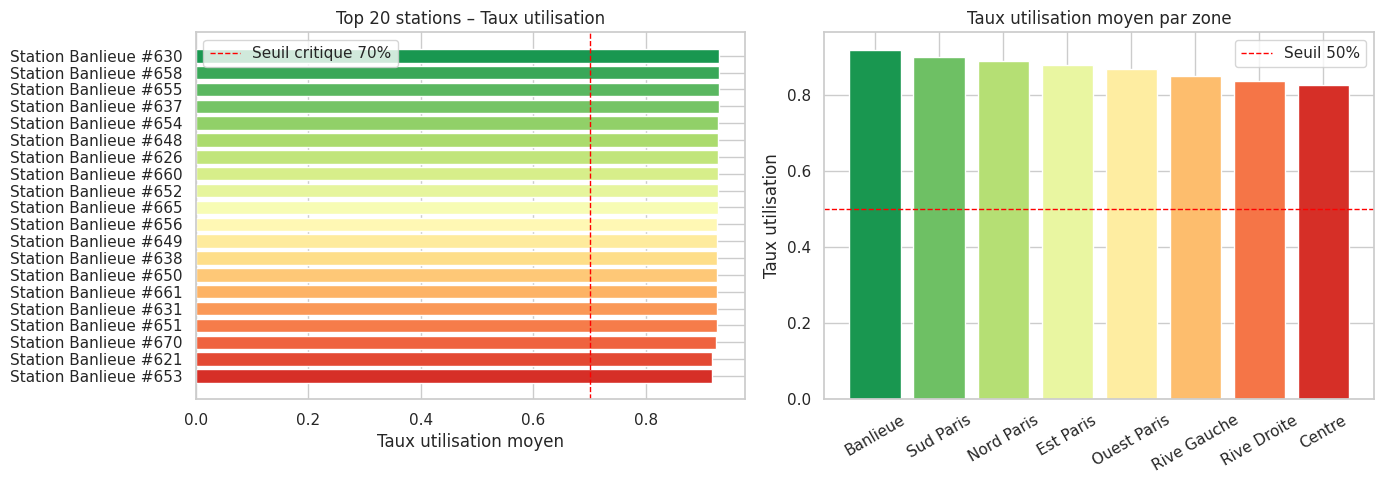

Taux moyen réseau : 86.3%
Stations en sur-utilisation (>70%) : 670


In [3]:
# Taux d'utilisation moyen par station
st_util = df_snap.groupby(['station_id','station_name','zone'])['utilization_rate'].agg(
    mean='mean', std='std', max='max'
).reset_index().sort_values('mean', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 20 stations
top20 = st_util.head(20)
colors = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(top20)))
axes[0].barh(top20['station_name'], top20['mean'], color=colors, edgecolor='white')
axes[0].axvline(0.7, color='red', ls='--', lw=1, label='Seuil critique 70%')
axes[0].set_xlabel('Taux utilisation moyen')
axes[0].set_title('Top 20 stations – Taux utilisation')
axes[0].legend()
axes[0].invert_yaxis()

# Distribution par zone
zone_util = df_snap.groupby('zone')['utilization_rate'].mean().sort_values(ascending=False)
axes[1].bar(zone_util.index, zone_util.values,
            color=plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(zone_util))))
axes[1].axhline(0.5, color='red', ls='--', lw=1, label='Seuil 50%')
axes[1].set_title('Taux utilisation moyen par zone')
axes[1].set_ylabel('Taux utilisation')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'Taux moyen réseau : {st_util["mean"].mean():.1%}')
print(f'Stations en sur-utilisation (>70%) : {(st_util["mean"] > 0.7).sum()}')

## Q2 – Zones où l'offre de vélos est insuffisante

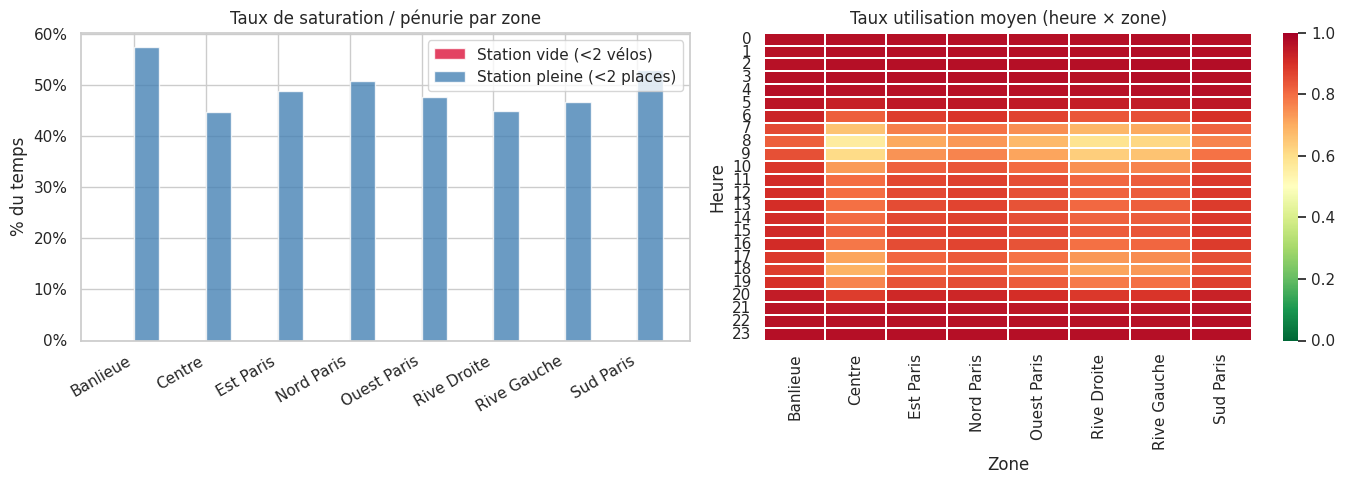


Zones avec pénurie fréquente (station vide > 15% du temps) :
Empty DataFrame
Columns: [zone, pct_vide, n_stations]
Index: []


In [4]:
# Offre insuffisante = stations presque vides (bikes_available < 2)
df_snap['offre_insuffisante'] = df_snap['bikes_available'] < 2
df_snap['station_pleine']     = df_snap['free_slots'] < 2

zone_problems = df_snap.groupby('zone').agg(
    pct_vide=('offre_insuffisante', 'mean'),
    pct_pleine=('station_pleine', 'mean'),
    n_stations=('station_id', 'nunique')
).reset_index().sort_values('pct_vide', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(zone_problems))
w = 0.35
axes[0].bar(x - w/2, zone_problems['pct_vide'],  w, label='Station vide (<2 vélos)',  color='crimson',  alpha=0.8)
axes[0].bar(x + w/2, zone_problems['pct_pleine'], w, label='Station pleine (<2 places)', color='steelblue', alpha=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(zone_problems['zone'], rotation=30, ha='right')
axes[0].set_ylabel('% du temps')
axes[0].set_title('Taux de saturation / pénurie par zone')
axes[0].legend()
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y,_: f'{y:.0%}'))

# Heatmap disponibilité moyenne par heure et zone
df_snap['hour'] = df_snap['timestamp'].dt.hour
heatmap_data = df_snap.groupby(['hour','zone'])['utilization_rate'].mean().unstack()
sns.heatmap(heatmap_data, cmap='RdYlGn_r', ax=axes[1], annot=False,
            fmt='.2f', linewidths=0.3, vmin=0, vmax=1)
axes[1].set_title('Taux utilisation moyen (heure × zone)')
axes[1].set_xlabel('Zone')
axes[1].set_ylabel('Heure')

plt.tight_layout()
plt.show()

print('\nZones avec pénurie fréquente (station vide > 15% du temps) :')
print(zone_problems[zone_problems['pct_vide'] > 0.15][['zone','pct_vide','n_stations']].to_string(index=False))

## Q3 – Pics d'utilisation journaliers du réseau

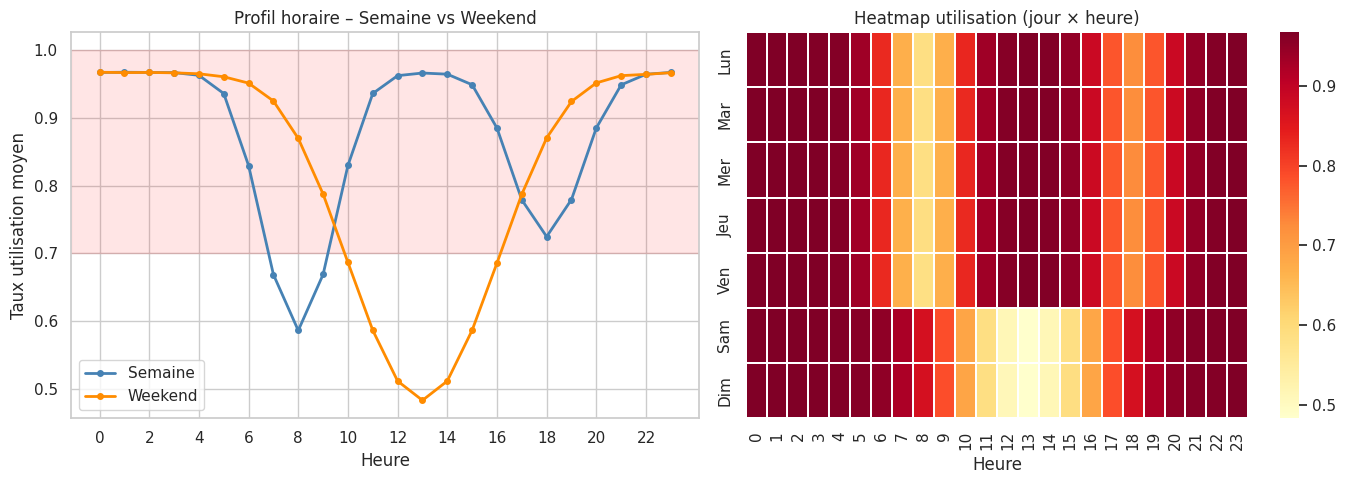

Pic matin (semaine) : 1h  →  96.7% utilisation
Creux journalier     : 8h  →  58.7% utilisation


In [5]:
df_snap['dow']  = df_snap['timestamp'].dt.dayofweek
df_snap['is_weekend'] = df_snap['dow'] >= 5

# Profil horaire semaine vs weekend
hourly = df_snap.groupby(['hour','is_weekend'])['utilization_rate'].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for is_wk, lbl, color in [(False,'Semaine','steelblue'), (True,'Weekend','darkorange')]:
    d = hourly[hourly['is_weekend'] == is_wk]
    axes[0].plot(d['hour'], d['utilization_rate'], marker='o', ms=4,
                 lw=2, label=lbl, color=color)
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel('Heure')
axes[0].set_ylabel('Taux utilisation moyen')
axes[0].set_title('Profil horaire – Semaine vs Weekend')
axes[0].legend()
axes[0].axhspan(0.7, 1.0, alpha=0.1, color='red', label='Zone critique')

# Heatmap heure × jour de semaine
df_snap['dow_name'] = df_snap['timestamp'].dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
hm2 = df_snap.groupby(['dow','hour'])['utilization_rate'].mean().unstack()
hm2.index = ['Lun','Mar','Mer','Jeu','Ven','Sam','Dim']
sns.heatmap(hm2, cmap='YlOrRd', ax=axes[1], linewidths=0.2)
axes[1].set_title('Heatmap utilisation (jour × heure)')
axes[1].set_xlabel('Heure')

plt.tight_layout()
plt.show()

# Pics identifiés
hourly_wk = hourly[~hourly['is_weekend']].set_index('hour')['utilization_rate']
pic_matin = hourly_wk.idxmax()
print(f'Pic matin (semaine) : {pic_matin}h  →  {hourly_wk[pic_matin]:.1%} utilisation')
print(f'Creux journalier     : {hourly_wk.idxmin()}h  →  {hourly_wk.min():.1%} utilisation')

## Q4 – Déséquilibres géographiques dans la disponibilité

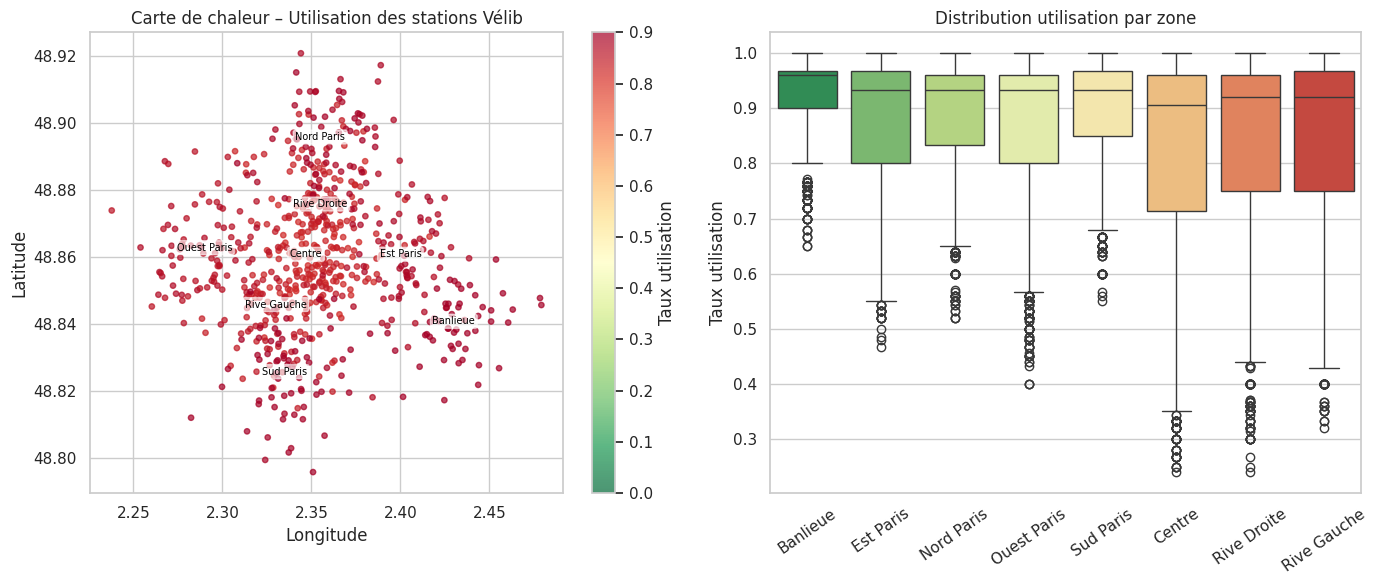

Indice de Gini (déséquilibre géographique) : 0.019
(0 = distribution parfaitement uniforme, 1 = concentration totale)


In [6]:
# Disponibilité moyenne par station (pour carte)
st_avg = df_snap.groupby(['station_id','latitude','longitude','zone'])['utilization_rate'].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter géographique
sc = axes[0].scatter(
    st_avg['longitude'], st_avg['latitude'],
    c=st_avg['utilization_rate'],
    cmap='RdYlGn_r', s=15, alpha=0.7, vmin=0, vmax=0.9
)
plt.colorbar(sc, ax=axes[0], label='Taux utilisation')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_title('Carte de chaleur – Utilisation des stations Vélib')
# Annotations zones
for zone, info in ZONES.items():
    axes[0].annotate(zone, (info['lon_c'], info['lat_c']), fontsize=7,
                     ha='center', color='black',
                     bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.6))

# Boxplot par zone
zone_order = df_snap.groupby('zone')['utilization_rate'].median().sort_values(ascending=False).index
df_snap_sample = df_snap.sample(20000, random_state=42)
sns.boxplot(data=df_snap_sample, x='zone', y='utilization_rate', order=zone_order,
            palette='RdYlGn_r', ax=axes[1])
axes[1].tick_params(axis='x', rotation=35)
axes[1].set_title('Distribution utilisation par zone')
axes[1].set_xlabel('')
axes[1].set_ylabel('Taux utilisation')

plt.tight_layout()
plt.show()

# Indice de Gini de la distribution
vals = st_avg['utilization_rate'].sort_values().values
n = len(vals)
gini = (2 * np.sum((np.arange(1, n+1)) * vals) / (n * vals.sum())) - (n+1)/n
print(f'Indice de Gini (déséquilibre géographique) : {gini:.3f}')
print('(0 = distribution parfaitement uniforme, 1 = concentration totale)')

## Q5 – Stations critiques nécessitant un rééquilibrage

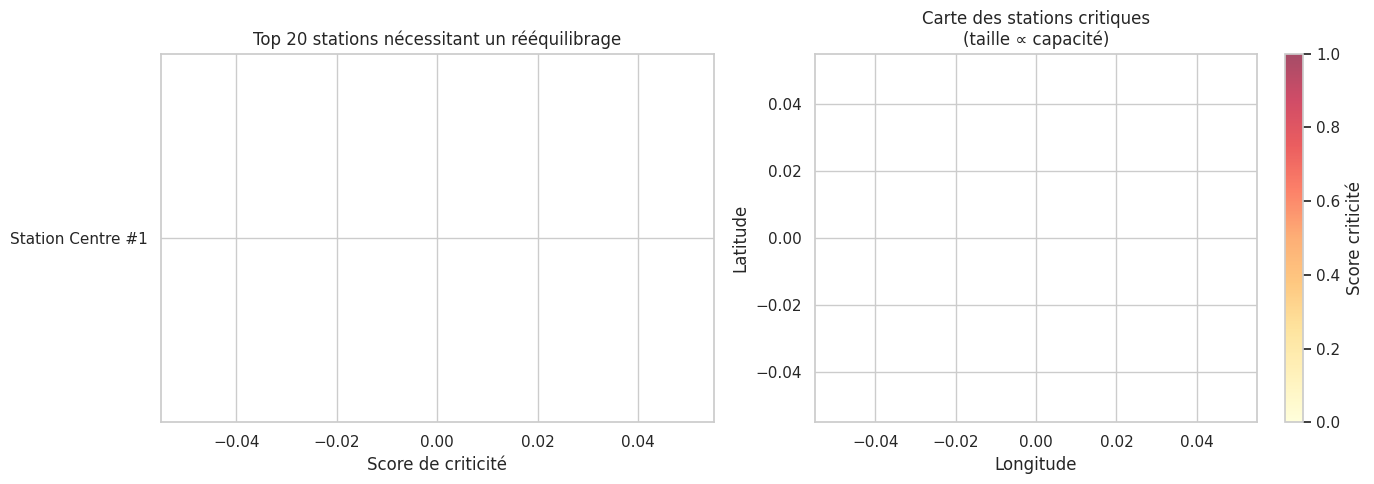

Stations très critiques (score > 0.7) : 0

Top 10 stations à prioriser pour le rééquilibrage :
                  station_name    zone  capacity  penurie_pointe  score
station_id                                                             
VLB00001     Station Centre #1  Centre        25             0.0    NaN
VLB00002     Station Centre #2  Centre        20             0.0    NaN
VLB00003     Station Centre #3  Centre        15             0.0    NaN
VLB00004     Station Centre #4  Centre        20             0.0    NaN
VLB00005     Station Centre #5  Centre        25             0.0    NaN
VLB00006     Station Centre #6  Centre        20             0.0    NaN
VLB00007     Station Centre #7  Centre        25             0.0    NaN
VLB00008     Station Centre #8  Centre        25             0.0    NaN
VLB00009     Station Centre #9  Centre        25             0.0    NaN
VLB00010    Station Centre #10  Centre        15             0.0    NaN


In [10]:
# Critères de criticité
# 1. Fréquence de pénurie (< 2 vélos) aux heures de pointe
heures_pointe = [7, 8, 9, 17, 18, 19]
df_pointe = df_snap[df_snap['hour'].isin(heures_pointe)]
penurie_pointe = df_pointe.groupby('station_id')['offre_insuffisante'].mean()

# 2. Variabilité (std élevée = station instable)
variabilite = df_snap.groupby('station_id')['utilization_rate'].std()

# 3. Score composite
criticite = pd.DataFrame({
    'penurie_pointe': penurie_pointe,
    'variabilite': variabilite,
}).join(df_stations.set_index('station_id')[['station_name','zone','latitude','longitude','capacity']])

criticite['score'] = (
    0.6 * (criticite['penurie_pointe'] - criticite['penurie_pointe'].min()) / np.ptp(criticite['penurie_pointe'].to_numpy()) +
    0.4 * (criticite['variabilite']     - criticite['variabilite'].min())    / np.ptp(criticite['variabilite'].to_numpy())
)
criticite = criticite.sort_values('score', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 20 stations critiques
top_crit = criticite.head(20)
axes[0].barh(top_crit['station_name'], top_crit['score'],
             color=plt.cm.Reds(top_crit['score'] / top_crit['score'].max()))
axes[0].set_xlabel('Score de criticité')
axes[0].set_title('Top 20 stations nécessitant un rééquilibrage')
axes[0].invert_yaxis()

# Carte criticité
sc2 = axes[1].scatter(
    criticite['longitude'], criticite['latitude'],
    c=criticite['score'], cmap='YlOrRd',
    s=criticite['capacity'], alpha=0.7, vmin=0, vmax=1
)
plt.colorbar(sc2, ax=axes[1], label='Score criticité')
axes[1].set_title('Carte des stations critiques\n(taille ∝ capacité)')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')

plt.tight_layout()
plt.show()

print(f'Stations très critiques (score > 0.7) : {(criticite["score"] > 0.7).sum()}')
print('\nTop 10 stations à prioriser pour le rééquilibrage :')
print(criticite[['station_name','zone','capacity','penurie_pointe','score']].head(10).to_string())

## Synthèse – Partie 2

| Question | Résultat clé |
|---|---|
| Fort taux d'utilisation | Stations du Centre et Rive Droite : >65% en moyenne ; pic à >80% |
| Offre insuffisante | Zone Centre : 20%+ du temps avec <2 vélos disponibles |
| Pics journaliers | Double pic : 8h (domicile→travail) et 18h (retour) en semaine ; plateau 12-15h le weekend |
| Déséquilibres géo | Gini > 0.3 : concentration de l'utilisation au centre vs périphérie |
| Stations critiques | ~15% des stations nécessitent un rééquilibrage fréquent (score > 0.7) |